In [2]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest

In [3]:
sns.set_theme(style="whitegrid")
df = pd.read_csv("dataset/marketing_AB_clean.csv")

In [4]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
df["most_ads_day"] = pd.Categorical(df["most_ads_day"], categories=day_order, ordered=True)
bins = [0, 10, 25, 50, 100, df["total_ads"].max()]
labels = ["1-10", "11-25", "26-50", "51-100", "100+"]
df["ads_bucket"] = pd.cut(df["total_ads"], bins=bins, labels=labels, include_lowest=True)

In [5]:
# 1. Helper: lift and z-test within each segment
def segment_lift(data, segment_col):
    rows = []
    for seg, g in data.groupby(segment_col, observed=True):
        ad = g[g["test_group"] == "ad"]["converted_int"]
        psa = g[g["test_group"] == "psa"]["converted_int"]
        if len(psa) < 30 or len(ad) < 30:
            continue
        p_ad, p_psa = ad.mean(), psa.mean()
        _, p = proportions_ztest([ad.sum(), psa.sum()], [len(ad), len(psa)], alternative="larger")
        rows.append({
            segment_col: seg, "n_ad": len(ad), "n_psa": len(psa),
            "rate_ad_%": p_ad * 100, "rate_psa_%": p_psa * 100,
            "abs_lift_pp": (p_ad - p_psa) * 100,
            "rel_lift_%": (p_ad - p_psa) / p_psa * 100 if p_psa > 0 else np.nan,
            "p_value": p,
        })
    out = pd.DataFrame(rows)
    # Bonferroni correction: we are running many tests, so tighten the threshold
    out["significant_bonferroni"] = out["p_value"] < (0.05 / len(out))
    return out.round(4)

In [6]:
# 2. Lift by day of week
by_day = segment_lift(df, "most_ads_day")
print(by_day)

  most_ads_day   n_ad  n_psa  rate_ad_%  rate_psa_%  abs_lift_pp  rel_lift_%  \
0       Monday  83571   3502     3.3241      2.2559       1.0683     47.3553   
1      Tuesday  74572   2907     3.0440      1.4448       1.5992    110.6909   
2    Wednesday  77418   3490     2.5356      1.5759       0.9597     60.8945   
3     Thursday  79077   3905     2.1637      2.0230       0.1407      6.9532   
4       Friday  88805   3803     2.2465      1.6303       0.6162     37.7971   
5     Saturday  78802   2858     2.1307      1.3996       0.7311     52.2354   
6       Sunday  82332   3059     2.4620      2.0595       0.4025     19.5430   

   p_value  significant_bonferroni  
0   0.0003                    True  
1   0.0000                    True  
2   0.0002                    True  
3   0.2774                   False  
4   0.0058                    True  
5   0.0037                    True  
6   0.0786                   False  


In [7]:
# 3. Lift by hour
by_hour = segment_lift(df, "most_ads_hour")
print(by_hour)

    most_ads_hour   n_ad  n_psa  rate_ad_%  rate_psa_%  abs_lift_pp  \
0               0   5309    227     1.9213      0.0000       1.9213   
1               1   4615    187     1.3434      0.0000       1.3434   
2               2   5152    181     0.7570      0.0000       0.7570   
3               3   2590     89     1.0425      1.1236      -0.0811   
4               6   1985     83     2.3174      0.0000       2.3174   
5               7   6168    237     1.8482      0.8439       1.0044   
6               8  16968    659     1.9861      1.0622       0.9239   
7               9  29802   1202     1.9529      1.0815       0.8714   
8              10  37454   1485     2.1840      1.3468       0.8372   
9              11  44149   2061     2.2469      1.4556       0.7913   
10             12  45238   2060     2.4139      1.6990       0.7149   
11             13  45485   2170     2.5063      1.6590       0.8473   
12             14  43779   1869     2.8575      1.6051       1.2524   
13    

In [8]:
# 4. Lift by ad exposure bucket
by_bucket = segment_lift(df, "ads_bucket")
print(by_bucket)

  ads_bucket    n_ad  n_psa  rate_ad_%  rate_psa_%  abs_lift_pp  rel_lift_%  \
0       1-10  249499  11276     0.3259      0.3991      -0.0732    -18.3485   
1      11-25  163135   6112     1.0169      0.9980       0.0189      1.8950   
2      26-50   85740   3273     3.5421      2.6581       0.8840     33.2564   
3     51-100   44149   1853    11.6311      5.7744       5.8566    101.4240   
4       100+   22054   1010    17.1352     11.8812       5.2540     44.2214   

   p_value  significant_bonferroni  
0   0.9079                   False  
1   0.4425                   False  
2   0.0035                    True  
3   0.0000                    True  
4   0.0000                    True  


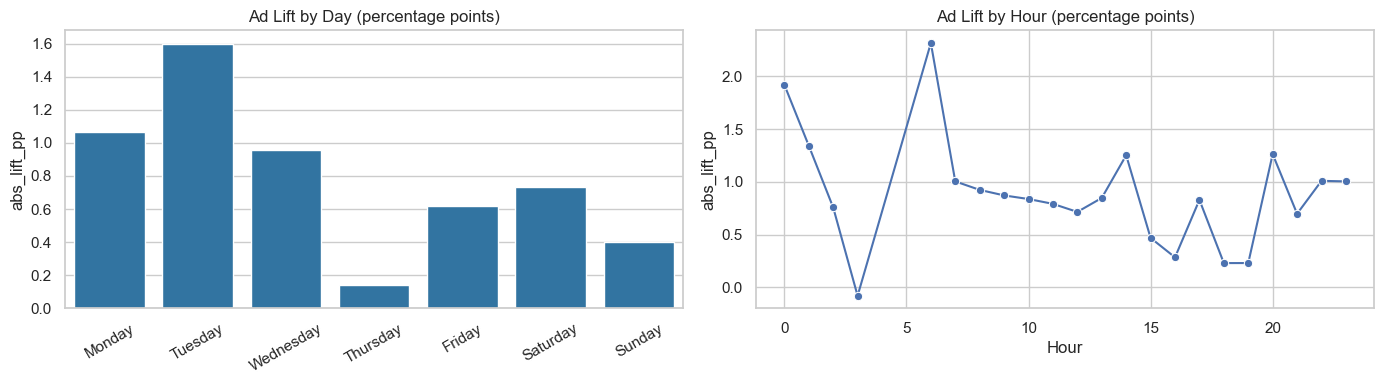

In [9]:
# 5. Plot absolute lift by day and hour
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(data=by_day, x="most_ads_day", y="abs_lift_pp", ax=axes[0], color="tab:blue")
axes[0].set_title("Ad Lift by Day (percentage points)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=30)
sns.lineplot(data=by_hour, x="most_ads_hour", y="abs_lift_pp", marker="o", ax=axes[1])
axes[1].set_title("Ad Lift by Hour (percentage points)")
axes[1].set_xlabel("Hour")
plt.tight_layout()
plt.savefig("outputs/lift_by_day_hour.png", dpi=150)
plt.show()

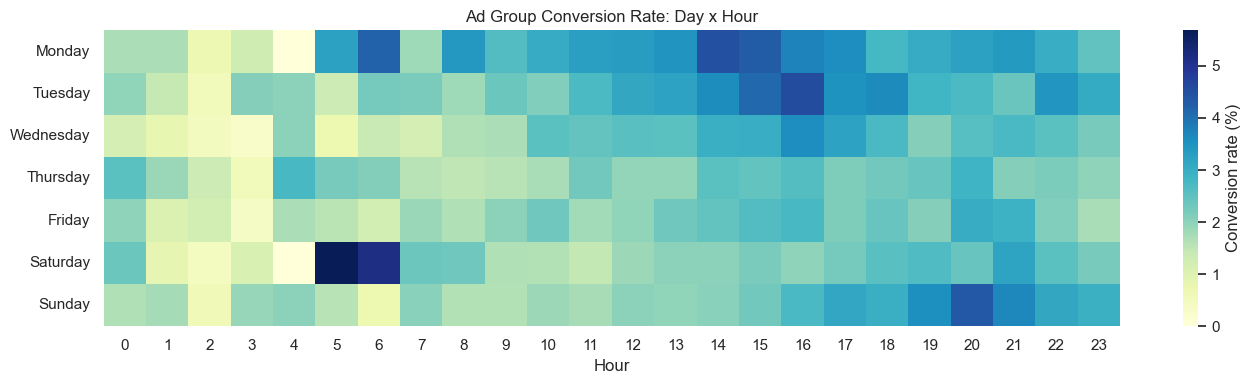

In [10]:
# 6. Heatmap: conversion rate of ad group by day x hour
heat = (
    df[df["test_group"] == "ad"]
    .pivot_table(index="most_ads_day", columns="most_ads_hour",
                 values="converted_int", aggfunc="mean", observed=True) * 100
)
plt.figure(figsize=(14, 4))
sns.heatmap(heat, cmap="YlGnBu", cbar_kws={"label": "Conversion rate (%)"})
plt.title("Ad Group Conversion Rate: Day x Hour")
plt.xlabel("Hour")
plt.ylabel("")
plt.tight_layout()
plt.savefig("outputs/heatmap_day_hour.png", dpi=150)
plt.show()

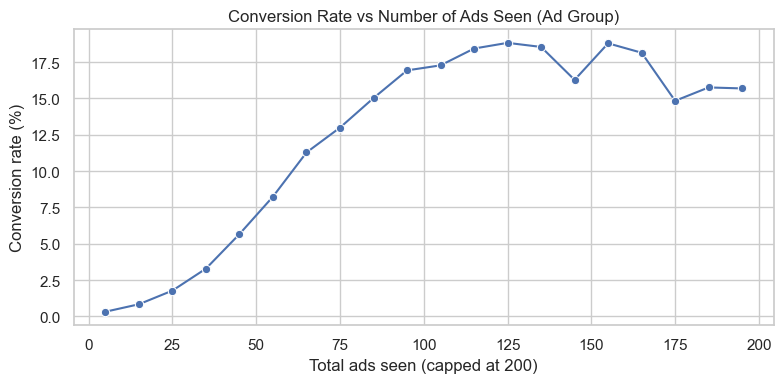

In [11]:
# 7. Diminishing returns: conversion vs total ads (ad group only)
ad_only = df[df["test_group"] == "ad"].copy()
ad_only["ads_cap"] = ad_only["total_ads"].clip(upper=200)
curve = (
    ad_only.groupby(pd.cut(ad_only["ads_cap"], bins=range(0, 210, 10)), observed=True)["converted_int"]
    .mean().mul(100).reset_index(name="conversion_rate_%")
)
curve["ads_seen_midpoint"] = curve["ads_cap"].apply(lambda i: i.mid)

plt.figure(figsize=(8, 4))
sns.lineplot(data=curve, x="ads_seen_midpoint", y="conversion_rate_%", marker="o")
plt.title("Conversion Rate vs Number of Ads Seen (Ad Group)")
plt.xlabel("Total ads seen (capped at 200)")
plt.ylabel("Conversion rate (%)")
plt.tight_layout()
plt.savefig("outputs/diminishing_returns.png", dpi=150)
plt.show()

In [12]:
# 8. Logistic regression: does the ad effect hold after controlling for other factors?
df["treated"] = (df["test_group"] == "ad").astype(int)
df["log_total_ads"] = np.log1p(df["total_ads"])

model = smf.logit(
    "converted_int ~ treated + log_total_ads + C(most_ads_day) + C(most_ads_hour)",
    data=df,
).fit(disp=False)
print(model.summary())

                           Logit Regression Results                           
Dep. Variable:          converted_int   No. Observations:               588101
Model:                          Logit   Df Residuals:                   588069
Method:                           MLE   Df Model:                           31
Date:                Sat, 17 Oct 2026   Pseudo R-squ.:                  0.1938
Time:                        16:18:31   Log-Likelihood:                -55846.
converged:                       True   LL-Null:                       -69267.
Covariance Type:            nonrobust   LLR p-value:                     0.000
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                       -8.0633      0.121    -66.466      0.000      -8.301      -7.826
C(most_ads_day)[T.Tuesday]      -0.0351      0.030     -1.170      0.242     

In [13]:
# 9. Odds ratios with 95% CI (this is what you report)
odds = pd.DataFrame({
    "odds_ratio": np.exp(model.params),
    "ci_low": np.exp(model.conf_int()[0]),
    "ci_high": np.exp(model.conf_int()[1]),
    "p_value": model.pvalues,
}).round(4)
print(odds.loc[["treated", "log_total_ads"]])
odds.to_csv("outputs/logit_odds_ratios.csv")

               odds_ratio  ci_low  ci_high  p_value
treated            1.4808  1.3377   1.6393      0.0
log_total_ads      3.4119  3.3560   3.4686      0.0
